In [30]:
import os

print("Current folder:", os.getcwd())

print("\nCSV files in this folder:")
for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

Current folder: C:\Users\PC\DSN

CSV files in this folder:
NHANES_Combined_Features.csv
NHANES_Combined_Features1.csv
NHANES_US_2021_2023.csv


In [31]:
import pandas as pd

nhanes = pd.read_csv("NHANES_US_2021_2023.csv")

print("Dataset loaded:", nhanes.shape)
display(nhanes.head())

Dataset loaded: (8860, 48)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,42.8,NaN,42.0,NaN,35.7,NaN,98.3,NaN,102.9,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,38.5,NaN,38.7,NaN,33.7,NaN,114.7,NaN,112.4,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,38.5,NaN,35.5,NaN,36.3,NaN,93.5,NaN,98.0,NaN
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,NaN,NaN,25.4,NaN,23.4,NaN,70.4,NaN,NaN,NaN
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN


In [32]:
nhanes.head(5)

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,42.8,NaN,42.0,NaN,35.7,NaN,98.3,NaN,102.9,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,38.5,NaN,38.7,NaN,33.7,NaN,114.7,NaN,112.4,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,38.5,NaN,35.5,NaN,36.3,NaN,93.5,NaN,98.0,NaN
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,NaN,NaN,25.4,NaN,23.4,NaN,70.4,NaN,NaN,NaN
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN


In [33]:
# Missing-value report
missing_report = pd.DataFrame({
    "Missing Count": nhanes.isna().sum(),
    "Missing Percentage": (
        nhanes.isna().mean() * 100
    ).round(2),
    "Available Count": nhanes.notna().sum()
})

missing_report = missing_report.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage,Available Count
BMIHEAD,8860,100.00,0
BMIRECUM,8842,99.80,18
BMXHEAD,8790,99.21,70
BMIHT,8726,98.49,134
BMIARML,8660,97.74,200
BMIARMC,8655,97.69,205
RIDAGEMN,8608,97.16,252
BMIWT,8515,96.11,345
BMIWAIST,8513,96.08,347
BMIHIP,8499,95.93,361


In [34]:
print("Total columns:", len(nhanes.columns))
print(nhanes.columns.tolist())

Total columns: 48
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP']


In [35]:
print(nhanes["BMDBMIC"].value_counts(dropna=False).sort_index())

print("\nAge distribution:")
print(nhanes["RIDAGEYR"].describe())

print("\nMissing values in key variables:")
print(
    nhanes[
        ["RIDAGEYR", "RIAGENDR", "RIDRETH3",
         "INDFMPIR", "BMDBMIC"]
    ].isnull().sum()
)

BMDBMIC
1.0      92
2.0    1469
3.0     372
4.0     559
NaN    6368
Name: count, dtype: int64

Age distribution:
count    8.860000e+03
mean     3.990542e+01
std      2.517546e+01
min      5.397605e-79
25%      1.500000e+01
50%      4.000000e+01
75%      6.300000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64

Missing values in key variables:
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
INDFMPIR    1147
BMDBMIC     6368
dtype: int64


In [36]:
# Select children and adolescents aged 2–19
children = nhanes[
    nhanes["RIDAGEYR"].between(2, 19)
].copy()

# Keep participants with a valid obesity category
children = children.dropna(subset=["BMDBMIC"]).copy()

# Create a binary target: 1 = obese, 0 = not obese
children["OBESE"] = (children["BMDBMIC"] == 4).astype(int)

print("Final number of participants:", len(children))
print("\nObesity outcome:")
print(children["OBESE"].value_counts())

print("\nObesity percentage:")
print(round(children["OBESE"].mean() * 100, 2), "%")

print("\nAge range:")
print(children["RIDAGEYR"].min(), "to", children["RIDAGEYR"].max())

Final number of participants: 2492

Obesity outcome:
OBESE
0    1933
1     559
Name: count, dtype: int64

Obesity percentage:
22.43 %

Age range:
2.0 to 19.0


In [37]:
children

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP,OBESE
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,NaN,25.4,NaN,23.4,NaN,70.4,NaN,NaN,NaN,1
20,130401.0,12.0,2.0,1.0,18.0,NaN,3.0,3.0,1.0,222.0,...,NaN,38.1,NaN,33.0,NaN,100.3,NaN,107.5,NaN,0
22,130403.0,12.0,2.0,2.0,12.0,NaN,2.0,2.0,1.0,147.0,...,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,1
24,130405.0,12.0,2.0,2.0,3.0,NaN,4.0,4.0,2.0,41.0,...,NaN,22.0,NaN,16.6,NaN,51.1,NaN,NaN,NaN,0
29,130411.0,12.0,2.0,1.0,4.0,NaN,3.0,3.0,2.0,50.0,...,NaN,20.4,NaN,17.6,NaN,52.0,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8832,142277.0,12.0,2.0,1.0,2.0,NaN,2.0,2.0,1.0,30.0,...,NaN,19.0,NaN,18.6,NaN,56.0,NaN,NaN,NaN,1
8836,142282.0,12.0,2.0,2.0,2.0,NaN,5.0,7.0,1.0,37.0,...,NaN,21.4,NaN,16.8,NaN,51.7,NaN,NaN,NaN,0
8844,142292.0,12.0,2.0,1.0,10.0,NaN,5.0,7.0,2.0,120.0,...,NaN,27.8,NaN,19.5,NaN,57.7,NaN,NaN,NaN,0
8853,142304.0,12.0,2.0,1.0,14.0,NaN,2.0,2.0,1.0,180.0,...,NaN,37.0,NaN,21.7,NaN,69.6,NaN,81.4,NaN,0


In [38]:


folder = r"C:\Users\PC\Downloads"

files = {
    "income": "INQ_L.xpt",
    "food_security": "FSQ_L.xpt",
    "diet_behavior": "DBQ_L.xpt",
    "physical_activity": "PAQY_L.xpt"
}

extra_data = {}

for name, filename in files.items():
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        df = pd.read_sas(path, format="xport")
        extra_data[name] = df
        print(f"{name}: {df.shape}")
    else:
        print(f"File not found: {path}")

income: (11933, 5)
food_security: (11933, 32)
diet_behavior: (11933, 27)
physical_activity: (3109, 3)


In [39]:
for name, df in extra_data.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print(df.columns.tolist())


INCOME
Shape: (11933, 5)
['SEQN', 'INDFMMPI', 'INDFMMPC', 'INQ300', 'IND310']

FOOD_SECURITY
Shape: (11933, 32)
['SEQN', 'FSD032A', 'FSD032B', 'FSD032C', 'FSD041', 'FSD052', 'FSD061', 'FSD071', 'FSD081', 'FSD092', 'FSD102', 'FSDAD', 'FSD151', 'FSQ165', 'FSD165N', 'FSQ012', 'FSD012N', 'FSD230', 'FSD230N', 'FSD795', 'FSD225', 'FSD235', 'FSD162', 'FSQ760', 'FSD760N', 'FSQ653', 'FSD660ZC', 'FSD675', 'FSD680', 'FSD670ZC', 'FSQ690', 'FSQ695']

DIET_BEHAVIOR
Shape: (11933, 27)
['SEQN', 'DBQ010', 'DBD030', 'DBD041', 'DBD050', 'DBD055', 'DBD061', 'DBQ073A', 'DBQ073B', 'DBQ073C', 'DBQ073D', 'DBQ073E', 'DBQ073U', 'DBQ301', 'DBQ330', 'DBQ360', 'DBQ370', 'DBD381', 'DBQ390', 'DBQ400', 'DBD411', 'DBQ421', 'DBQ424', 'DBQ930', 'DBQ935', 'DBQ940', 'DBQ945']

PHYSICAL_ACTIVITY
Shape: (3109, 3)
['SEQN', 'PAQ706', 'PAQ711']


In [40]:
print(extra_data.keys())

dict_keys(['income', 'food_security', 'diet_behavior', 'physical_activity'])


In [41]:
print("Main NHANES shape:", nhanes.shape)
print("Main NHANES columns:", nhanes.columns.tolist())

print("\nAdditional NHANES files:")
for name, df in extra_data.items():
    print(f"{name}: {df.shape}")

Main NHANES shape: (8860, 48)
Main NHANES columns: ['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP']

Additional NHANES files:
income: (11933, 5)
food_security: (11933, 32)
diet_behavior: (11933, 27)
physical_activity: (3109, 3)


In [42]:


# Make a copy so the original dataset remains unchanged
nhanes_merged = nhanes.copy()

# Merge each additional NHANES dataset
for name, df in extra_data.items():

    # Confirm that SEQN exists in both datasets
    if "SEQN" not in nhanes_merged.columns:
        raise ValueError("The main NHANES dataset has no SEQN column.")

    if "SEQN" not in df.columns:
        print(f"Skipping {name}: SEQN column not found.")
        continue

    # Check whether SEQN uniquely identifies participants
    if df["SEQN"].duplicated().any():
        print(f"Warning: {name} contains duplicate SEQN values.")
        continue

    # Identify overlapping columns before merging
    overlapping = [
        col for col in df.columns
        if col in nhanes_merged.columns and col != "SEQN"
    ]

    if overlapping:
        print(f"Skipping {name}: overlapping columns: {overlapping}")
        continue

    # Add the additional features
    nhanes_merged = nhanes_merged.merge(
        df,
        on="SEQN",
        how="left",
        validate="one_to_one"
    )

    print(f"Merged {name}: {nhanes_merged.shape}")

print("\nFinal dataset shape:", nhanes_merged.shape)


Merged income: (8860, 52)
Merged food_security: (8860, 83)
Merged diet_behavior: (8860, 109)
Merged physical_activity: (8860, 111)

Final dataset shape: (8860, 111)


In [43]:

# Inspect the combined dataset
display(nhanes_merged.head())

print("Number of participants:", len(nhanes_merged))
print("Number of features:", len(nhanes_merged.columns))

# Missing values
missing = (
    nhanes_merged.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(missing[missing > 0].head(25))

# Confirm participant IDs remain unique
print(
    "Unique participant IDs:",
    nhanes_merged["SEQN"].nunique()
)

print(
    "Duplicate participant IDs:",
    nhanes_merged["SEQN"].duplicated().sum()
)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBQ400,DBD411,DBQ421,DBQ424,DBQ930,DBQ935,DBQ940,DBQ945,PAQ706,PAQ711
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,2.0,1.0,2.0,1.0,NaN,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,1.0,5.397605e-79,NaN,1.0,NaN,NaN,NaN,NaN,7.0,3.0
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,2.0


Number of participants: 8860
Number of features: 111


BMIHEAD     8860
DBQ073E     8847
DBQ073D     8847
BMIRECUM    8842
DBQ073C     8810
DBQ073U     8807
BMXHEAD     8790
DBQ073B     8753
BMIHT       8726
BMIARML     8660
BMIARMC     8655
RIDAGEMN    8608
FSD102      8575
FSD680      8534
FSQ695      8515
BMIWT       8515
BMIWAIST    8513
BMIHIP      8499
BMILEG      8464
FSD670ZC    8428
FSD660ZC    8428
FSD675      8428
BMXRECUM    8406
DBQ073A     8325
FSD760N     8232
dtype: int64

Unique participant IDs: 8860
Duplicate participant IDs: 0


In [44]:
nhanes_merged.to_csv(
    "NHANES_Combined_Features1.csv",
    index=False
)

In [45]:
nhanes_merged.head(5)

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBQ400,DBD411,DBQ421,DBQ424,DBQ930,DBQ935,DBQ940,DBQ945,PAQ706,PAQ711
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,2.0,1.0,2.0,1.0,NaN,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,1.0,5.397605e-79,NaN,1.0,NaN,NaN,NaN,NaN,7.0,3.0
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,2.0


In [46]:
nhanes_merged.isna().sum()

SEQN           0
SDDSRVYR       0
RIDSTATR       0
RIAGENDR       0
RIDAGEYR       0
            ... 
DBQ935      2245
DBQ940      2245
DBQ945      2245
PAQ706      6652
PAQ711      6652
Length: 111, dtype: int64

In [47]:

# Keep children and adolescents aged 2–19 years
child =nhanes_merged[nhanes_merged["RIDAGEYR"].between(2, 19)].copy()

print("Original dataset:", nhanes_merged.shape)
print("Children and adolescents:", child.shape)

print("\nAge range:")
print(child["RIDAGEYR"].describe())

print("\nParticipants by age:")
print(child["RIDAGEYR"].value_counts().sort_index())


Original dataset: (8860, 111)
Children and adolescents: (2547, 111)

Age range:
count    2547.000000
mean       10.561052
std         5.049607
min         2.000000
25%         6.000000
50%        11.000000
75%        15.000000
max        19.000000
Name: RIDAGEYR, dtype: float64

Participants by age:
RIDAGEYR
2.0     118
3.0     114
4.0     144
5.0     167
6.0     121
7.0     146
8.0     163
9.0     149
10.0    149
11.0    141
12.0    157
13.0    148
14.0    135
15.0    144
16.0    148
17.0    130
18.0    147
19.0    126
Name: count, dtype: int64


In [48]:

# Check missing values and categories in the obesity classification
print("BMDBMIC values, including missing:")
print(child["BMDBMIC"].value_counts(dropna=False).sort_index())

print("\nMissing BMI classifications:")
print(child["BMDBMIC"].isna().sum())

print("\nPercentage missing:")
print(round(child["BMDBMIC"].isna().mean() * 100, 2), "%")


BMDBMIC values, including missing:
BMDBMIC
1.0      92
2.0    1469
3.0     372
4.0     559
NaN      55
Name: count, dtype: int64

Missing BMI classifications:
55

Percentage missing:
2.16 %


In [49]:

# Create a modeling dataset with known BMI classifications
model_data = child.dropna(subset=["BMDBMIC"]).copy()

# Create the binary obesity target
model_data["OBESE"] = (
    model_data["BMDBMIC"] == 4
).astype(int)

print("Participants available for modeling:", len(model_data))

print("\nObesity target distribution:")
print(model_data["OBESE"].value_counts())

print("\nObesity target percentages:")
print(
    (model_data["OBESE"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nFinal dataset shape:", model_data.shape)





Participants available for modeling: 2492

Obesity target distribution:
OBESE
0    1933
1     559
Name: count, dtype: int64

Obesity target percentages:
OBESE
0    77.57
1    22.43
Name: proportion, dtype: float64

Final dataset shape: (2492, 112)


In [50]:
model_data.head(3)

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBD411,DBQ421,DBQ424,DBQ930,DBQ935,DBQ940,DBQ945,PAQ706,PAQ711,OBESE
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,5.397605e-79,NaN,1.0,NaN,NaN,NaN,NaN,7.0,3.0,1
20,130401.0,12.0,2.0,1.0,18.0,NaN,3.0,3.0,1.0,222.0,...,5.397605e-79,NaN,NaN,2.0,2.0,2.0,2.0,NaN,NaN,0
22,130403.0,12.0,2.0,2.0,12.0,NaN,2.0,2.0,1.0,147.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [51]:

# Display all column names
for i, col in enumerate(model_data.columns, start=1):
    print(i, col)


1 SEQN
2 SDDSRVYR
3 RIDSTATR
4 RIAGENDR
5 RIDAGEYR
6 RIDAGEMN
7 RIDRETH1
8 RIDRETH3
9 RIDEXMON
10 RIDEXAGM
11 DMQMILIZ
12 DMDBORN4
13 DMDYRUSR
14 DMDEDUC2
15 DMDMARTZ
16 RIDEXPRG
17 DMDHHSIZ
18 DMDHRGND
19 DMDHRAGZ
20 DMDHREDZ
21 DMDHRMAZ
22 DMDHSEDZ
23 WTINT2YR
24 WTMEC2YR
25 SDMVSTRA
26 SDMVPSU
27 INDFMPIR
28 BMDSTATS
29 BMXWT
30 BMIWT
31 BMXRECUM
32 BMIRECUM
33 BMXHEAD
34 BMIHEAD
35 BMXHT
36 BMIHT
37 BMXBMI
38 BMDBMIC
39 BMXLEG
40 BMILEG
41 BMXARML
42 BMIARML
43 BMXARMC
44 BMIARMC
45 BMXWAIST
46 BMIWAIST
47 BMXHIP
48 BMIHIP
49 INDFMMPI
50 INDFMMPC
51 INQ300
52 IND310
53 FSD032A
54 FSD032B
55 FSD032C
56 FSD041
57 FSD052
58 FSD061
59 FSD071
60 FSD081
61 FSD092
62 FSD102
63 FSDAD
64 FSD151
65 FSQ165
66 FSD165N
67 FSQ012
68 FSD012N
69 FSD230
70 FSD230N
71 FSD795
72 FSD225
73 FSD235
74 FSD162
75 FSQ760
76 FSD760N
77 FSQ653
78 FSD660ZC
79 FSD675
80 FSD680
81 FSD670ZC
82 FSQ690
83 FSQ695
84 DBQ010
85 DBD030
86 DBD041
87 DBD050
88 DBD055
89 DBD061
90 DBQ073A
91 DBQ073B
92 DBQ073C
93 DBQ073D

In [52]:
model_data.head(3)

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBD411,DBQ421,DBQ424,DBQ930,DBQ935,DBQ940,DBQ945,PAQ706,PAQ711,OBESE
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,5.397605e-79,NaN,1.0,NaN,NaN,NaN,NaN,7.0,3.0,1
20,130401.0,12.0,2.0,1.0,18.0,NaN,3.0,3.0,1.0,222.0,...,5.397605e-79,NaN,NaN,2.0,2.0,2.0,2.0,NaN,NaN,0
22,130403.0,12.0,2.0,2.0,12.0,NaN,2.0,2.0,1.0,147.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [53]:
important_columns = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3",
    "DMDHHSIZ", "DMDHRAGZ", "DMDHREDZ",
    "DMDHSEDZ", "INDFMPIR", "FSDAD",
    "FSD151", "FSQ165", "FSQ012", "FSD230",
    "DBQ360", "DBQ370", "DBQ390", "DBQ400",
    "DBQ421", "DBQ424", "OBESE"
]

for column in important_columns:
    if column in model_data.columns:
        print(column)

RIDAGEYR
RIAGENDR
RIDRETH3
DMDHHSIZ
DMDHRAGZ
DMDHREDZ
DMDHSEDZ
INDFMPIR
FSDAD
FSD151
FSQ165
FSQ012
FSD230
DBQ360
DBQ370
DBQ390
DBQ400
DBQ421
DBQ424
OBESE


# Columns and their meaning

In [55]:



columns_meaning = {
    "Column": [
        "RIDAGEYR", "RIAGENDR", "RIDRETH3", "DMDHHSIZ",
        "DMDHRAGZ", "DMDHREDZ", "INDFMPIR", "FSDAD",
        "FSD151", "FSQ165", "FSQ012", "FSD230",
        "DBQ360", "DBQ370", "DBQ390", "DBQ400",
        "DBQ421", "DBQ424", "PAQ706", "PAQ711", "OBESE"
    ],
    "Meaning": [
        "Child's age in years",
        "Sex recorded by NHANES",
        "Race and Hispanic origin",
        "Household size",
        "Household reference person's age",
        "Household reference person's education",
        "Family income-to-poverty ratio",
        "Household adult food-security category",
        "Emergency food assistance",
        "Household history of SNAP/food stamp benefits",
        "Recent SNAP/food stamp benefits",
        "Current SNAP/food stamp benefits",
        "School attendance",
        "School lunch availability",
        "School lunch price/assistance category",
        "School breakfast availability",
        "School breakfast price/assistance category",
        "Summer-program meal assistance",
        "Days physically active for at least 60 minutes in the past 7 days",
        "Hours per typical school-year day spent using screens",
        "Obesity status"
    ]
}

df_columns = pd.DataFrame(columns_meaning)

display(df_columns)


,Column,Meaning
0,RIDAGEYR,Child's age in years
1,RIAGENDR,Sex recorded by NHANES
2,RIDRETH3,Race and Hispanic origin
3,DMDHHSIZ,Household size
4,DMDHRAGZ,Household reference person's age
5,DMDHREDZ,Household reference person's education
6,INDFMPIR,Family income-to-poverty ratio
7,FSDAD,Household adult food-security category
8,FSD151,Emergency food assistance
9,FSQ165,Household history of SNAP/food stamp benefits


In [56]:
predictors = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDHHSIZ",
    "DMDHRAGZ",
    "DMDHREDZ",
    "INDFMPIR",
    "FSDAD",
    "FSD151",
    "FSQ165",
    "FSQ012",
    "FSD230",
    "DBQ360",
    "DBQ370",
    "DBQ390",
    "DBQ400",
    "DBQ421",
    "DBQ424"
    
]

target = "OBESE"

# Keep only columns that exist in your dataset
available = [c for c in predictors + [target]
             if c in model_data.columns]

analysis_data = model_data[available].copy()

print("Dataset shape:", analysis_data.shape)
print("\nMissing values:")
print(analysis_data.isnull().sum().sort_values(ascending=False))


Dataset shape: (2492, 19)

Missing values:
DBQ421      1535
FSD230      1523
DBQ424      1260
FSQ012      1103
DBQ390      1016
DBQ370       621
DBQ400       621
INDFMPIR     313
DBQ360       211
FSQ165       194
FSDAD        193
FSD151       188
DMDHREDZ     139
RIDAGEYR       0
RIAGENDR       0
DMDHRAGZ       0
DMDHHSIZ       0
RIDRETH3       0
OBESE          0
dtype: int64


In [57]:
analysis_data

,RIDAGEYR,RIAGENDR,RIDRETH3,DMDHHSIZ,DMDHRAGZ,DMDHREDZ,INDFMPIR,FSDAD,FSD151,FSQ165,FSQ012,FSD230,DBQ360,DBQ370,DBQ390,DBQ400,DBQ421,DBQ424,OBESE
3,5.0,2.0,7.0,2.0,2.0,2.0,1.53,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1
20,18.0,1.0,3.0,5.0,3.0,2.0,3.36,1.0,2.0,1.0,1.0,2.0,1.0,1.0,3.0,1.0,NaN,NaN,0
22,12.0,2.0,2.0,3.0,2.0,2.0,5.00,1.0,2.0,1.0,2.0,NaN,1.0,1.0,NaN,2.0,NaN,NaN,1
24,3.0,2.0,4.0,3.0,2.0,2.0,1.30,1.0,2.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0
29,4.0,1.0,3.0,4.0,2.0,2.0,2.16,1.0,2.0,1.0,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8832,2.0,1.0,2.0,7.0,2.0,1.0,0.23,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
8836,2.0,2.0,7.0,3.0,2.0,3.0,5.00,1.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
8844,10.0,1.0,7.0,7.0,2.0,2.0,0.17,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,NaN,2.0,0
8853,14.0,1.0,2.0,5.0,4.0,NaN,2.16,2.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,NaN,1.0,0


Dataset shape: (2492, 21)


,Missing Values,Missing Percentage (%)
RIDAGEYR,0,0.00
RIAGENDR,0,0.00
RIDRETH3,0,0.00
DMDHHSIZ,0,0.00
DMDHRAGZ,0,0.00
DMDHREDZ,139,5.58
INDFMPIR,313,12.56
FSDAD,193,7.74
FSD151,188,7.54
FSQ165,194,7.78


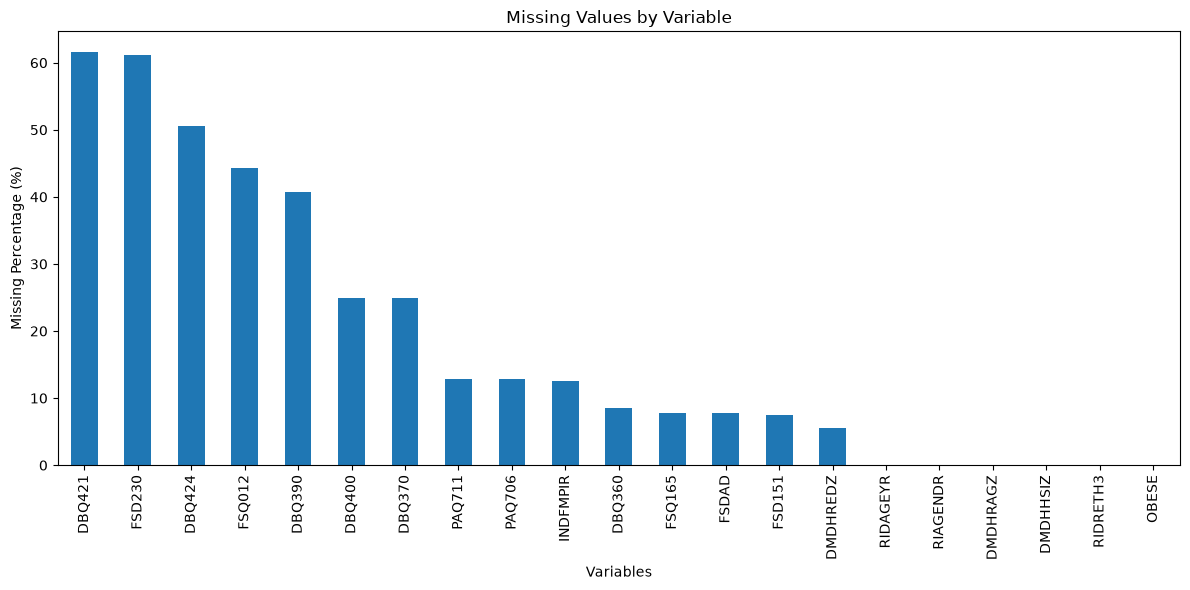

,RIDAGEYR,RIAGENDR,RIDRETH3,DMDHHSIZ,DMDHRAGZ,DMDHREDZ,INDFMPIR,FSDAD,FSD151,FSQ165,...,FSD230,DBQ360,DBQ370,DBQ390,DBQ400,DBQ421,DBQ424,PAQ706,PAQ711,OBESE
3,5.0,2.0,7.0,2.0,2.0,2.0,1.53,4.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,NaN,1.0,7.0,3.0,1
20,18.0,1.0,3.0,5.0,3.0,2.0,3.36,1.0,2.0,1.0,...,2.0,1.0,1.0,3.0,1.0,NaN,NaN,NaN,NaN,0
22,12.0,2.0,2.0,3.0,2.0,2.0,5.00,1.0,2.0,1.0,...,NaN,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,1
24,3.0,2.0,4.0,3.0,2.0,2.0,1.30,1.0,2.0,1.0,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,7.0,3.0,0
29,4.0,1.0,3.0,4.0,2.0,2.0,2.16,1.0,2.0,1.0,...,1.0,2.0,NaN,NaN,NaN,NaN,NaN,5.0,4.0,0


<class 'pandas.core.frame.DataFrame'>
Index: 2492 entries, 3 to 8855
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   RIDAGEYR  2492 non-null   float64
 1   RIAGENDR  2492 non-null   float64
 2   RIDRETH3  2492 non-null   float64
 3   DMDHHSIZ  2492 non-null   float64
 4   DMDHRAGZ  2492 non-null   float64
 5   DMDHREDZ  2353 non-null   float64
 6   INDFMPIR  2179 non-null   float64
 7   FSDAD     2299 non-null   float64
 8   FSD151    2304 non-null   float64
 9   FSQ165    2298 non-null   float64
 10  FSQ012    1389 non-null   float64
 11  FSD230    969 non-null    float64
 12  DBQ360    2281 non-null   float64
 13  DBQ370    1871 non-null   float64
 14  DBQ390    1476 non-null   float64
 15  DBQ400    1871 non-null   float64
 16  DBQ421    957 non-null    float64
 17  DBQ424    1232 non-null   float64
 18  PAQ706    2172 non-null   float64
 19  PAQ711    2172 non-null   float64
 20  OBESE     2492 non-null   int32  
d

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add the two physical activity variables
predictors = predictors + ["PAQ706", "PAQ711"]

target = "OBESE"

analysis_data = model_data[predictors + [target]].copy()

print("Dataset shape:", analysis_data.shape)



# Add physical activity variables and remove duplicates
predictors = list(dict.fromkeys(
    predictors + ["PAQ706", "PAQ711"]
))

target = "OBESE"

analysis_data = model_data[predictors + [target]].copy()



# Inspect missing values
missing_summary = pd.DataFrame({
    "Missing Values": analysis_data.isnull().sum(),
    "Missing Percentage (%)": (
        analysis_data.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)


plt.figure(figsize=(12, 6))

missing_summary["Missing Percentage (%)"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Missing Values by Variable")
plt.xlabel("Variables")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display the dataset
display(analysis_data.head())

# Display dataset dimensions and data types
analysis_data.info()


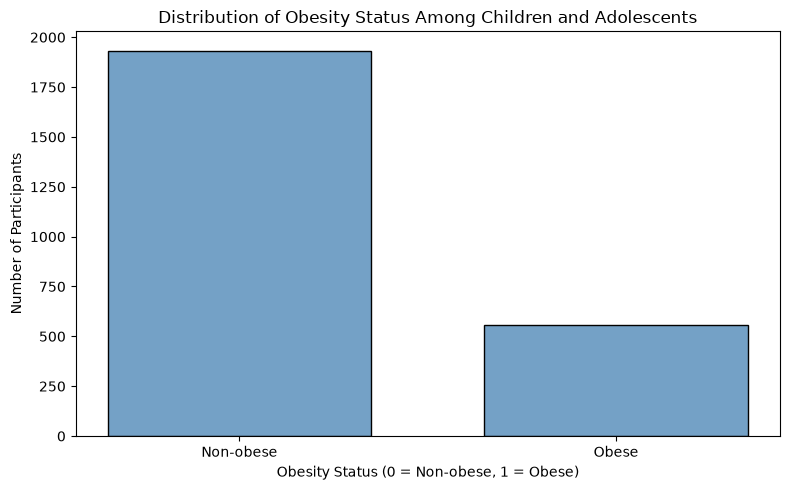

In [59]:
# Create a histogram of obesity status
plt.figure(figsize=(8, 5))

sns.histplot(
    data=analysis_data,
    x="OBESE",
    discrete=True,
    shrink=0.7,
    color="steelblue"
)

plt.title("Distribution of Obesity Status Among Children and Adolescents")
plt.xlabel("Obesity Status (0 = Non-obese, 1 = Obese)")
plt.ylabel("Number of Participants")
plt.xticks([0, 1], ["Non-obese", "Obese"])
plt.tight_layout()
plt.show()


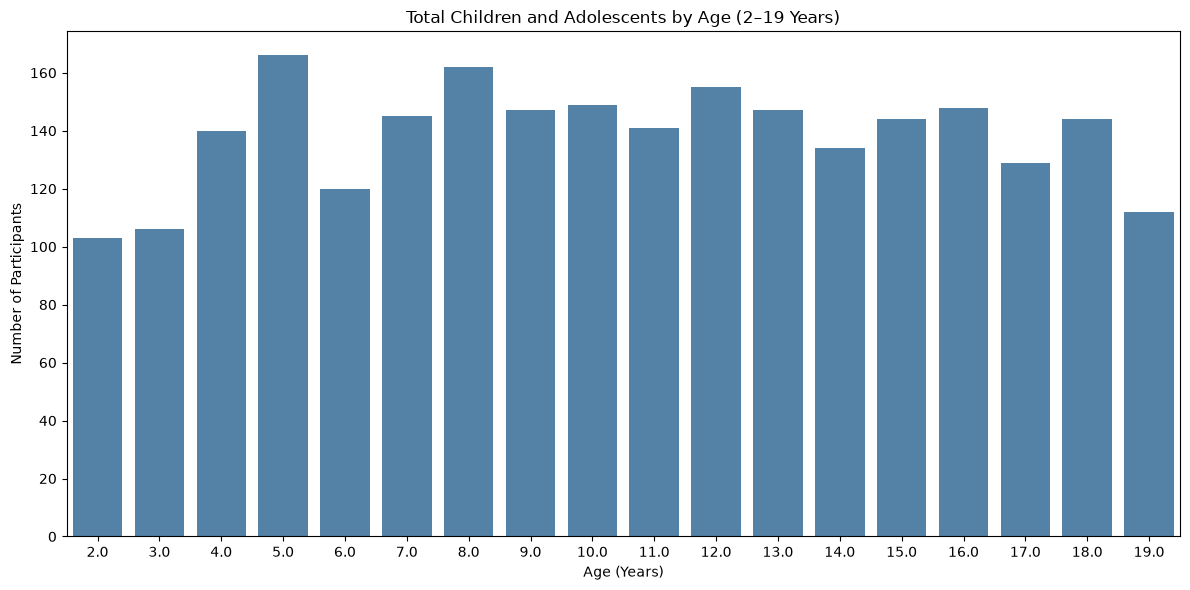

,Total Participants
Age (Years),
2.0,103
3.0,106
4.0,140
5.0,166
6.0,120
7.0,145
8.0,162
9.0,147
10.0,149


In [60]:
# Total children and adolescents by age (2–19 years)

# Count participants in each age group
children_by_age = (
    analysis_data[
        analysis_data["RIDAGEYR"].between(2, 19)
    ]["RIDAGEYR"]
    .value_counts()
    .sort_index()
)

# Plot bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=children_by_age.index,
    y=children_by_age.values,
    color="steelblue"
)

plt.title("Total Children and Adolescents by Age (2–19 Years)")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Participants")
plt.xticks(range(len(children_by_age)), children_by_age.index)
plt.tight_layout()
plt.show()

# Display exact counts
display(
    children_by_age
    .rename_axis("Age (Years)")
    .to_frame("Total Participants")
)

# CLASSIFICATION ANALYSIS

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


# MODEL TRAINING

In [64]:
""" Dropping the Obesity from 
    the dataset as its the dependent numerical value
    for Classification(Binary) number
"""
X = analysis_data.drop(columns=["OBESE"])
Y = analysis_data["OBESE"]


In [65]:
X.shape

(2492, 20)

In [171]:
print(X.columns.tolist())

['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDHHSIZ', 'DMDHRAGZ', 'DMDHREDZ', 'INDFMPIR', 'FSDAD', 'FSD151', 'FSQ165', 'FSQ012', 'FSD230', 'DBQ360', 'DBQ370', 'DBQ390', 'DBQ400', 'DBQ421', 'DBQ424', 'PAQ706', 'PAQ711']


In [175]:
for col in X.columns:
    print(f"\n{col}")
    print("Unique values:", analysis_data[col].unique()[:15])


RIDAGEYR
Unique values: [ 5. 18. 12.  3.  4.  7. 16. 15. 14. 11. 17. 19.  6. 10.  9.]

RIAGENDR
Unique values: [2. 1.]

RIDRETH3
Unique values: [7. 3. 2. 4. 1. 6.]

DMDHHSIZ
Unique values: [2. 5. 3. 4. 6. 7. 1.]

DMDHRAGZ
Unique values: [2. 3. 4. 1.]

DMDHREDZ
Unique values: [ 2.  1.  3. nan]

INDFMPIR
Unique values: [1.53 3.36 5.   1.3  2.16 0.63 0.02 2.64 1.02 1.99 3.42 1.14 4.22 1.15
 4.46]

FSDAD
Unique values: [ 4.  1.  3.  2. nan]

FSD151
Unique values: [ 1.  2. nan  7.  9.]

FSQ165
Unique values: [ 1.  2. nan  9.  7.]

FSQ012
Unique values: [ 1.  2. nan  9.]

FSD230
Unique values: [ 1.  2. nan  9.]

DBQ360
Unique values: [ 1. nan  2.  9.]

DBQ370
Unique values: [ 1. nan  2.  9.  7.]

DBQ390
Unique values: [ 1.  3. nan  2.  9.]

DBQ400
Unique values: [ 1.  2. nan  9.  7.]

DBQ421
Unique values: [nan  1.  2.  3.  9.]

DBQ424
Unique values: [ 1. nan  3.  2.  9.]

PAQ706
Unique values: [7.00000000e+00            nan 5.00000000e+00 3.00000000e+00
 6.00000000e+00 2.00000000e+00 5.397

In [66]:
Y.shape

(2492,)

# Spilting the Dataset to Trainng and Testing

In [68]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y, test_size =0.2, random_state = 42,  stratify=Y)

In [69]:
X_train.shape

(1993, 20)

In [70]:
X_test.shape

(499, 20)

In [71]:
Y_train.shape

(1993,)

In [72]:
Y_test.shape

(499,)

## Using Logistic Regression

In [74]:
model = Pipeline([
     ("imputer", SimpleImputer(strategy="median")),
     ("classifier", LogisticRegression(max_iter = 1000,  class_weight="balanced"))
      ])
model.fit(X_train,Y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [75]:
model_prediction = model.predict(X_test)
model_prediction

array([1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,

## Using Decision Tree Classifier

In [77]:
Model_decision = DecisionTreeClassifier()
Model_decision.fit(X_train, Y_train)

DecisionTreeClassifier()

In [78]:
Decision_prediction = Model_decision.predict(X_test)
Decision_prediction

array([0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0,

## Using Random Forest Classifier

In [80]:
Model_random = RandomForestClassifier(
     n_estimators=100,
    class_weight="balanced",
    random_state=42
)
Model_random.fit(X_train,Y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [81]:
Random_predict = Model_random.predict(X_test)
Random_predict

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,

## Using Gradient Boosting Classifier

In [83]:
imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

Model_gradient = GradientBoostingClassifier()
Model_gradient.fit(X_train, Y_train)

GradientBoostingClassifier()

In [84]:
Gradient_predict = Model_gradient.predict(X_test)
Gradient_predict

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

### Evaluation of models Using Accuracy_score, precision_score, Recall_score, F1_score, Roc_auc_score

In [86]:
Metrics = {
    "Accuracy_Score": accuracy_score,
    "Precision_score": precision_score,
    "Recall_score": recall_score,
    "F1_score": f1_score,
    "Roc_auc_score": roc_auc_score
}

Results = {}

for name,  func in Metrics.items():
    logistic_score = func(Y_test, model_prediction)
    decision_tree = func(Y_test, Decision_prediction)
    random_score = func(Y_test, Random_predict)
    gradient_score = func(Y_test, Gradient_predict)
    # Scoring scores in results
    Results[name] = {
        "Logistic Regression": logistic_score,
        "Decision Tree Classifier": decision_tree,
        "Random Forest Classifier": random_score,
        "Gradient Boosting Classifier": gradient_score
    }
    

In [87]:
Results

{'Accuracy_Score': {'Logistic Regression': 0.5651302605210421,
  'Decision Tree Classifier': 0.6713426853707415,
  'Random Forest Classifier': 0.7635270541082164,
  'Gradient Boosting Classifier': 0.7655310621242485},
 'Precision_score': {'Logistic Regression': 0.2821576763485477,
  'Decision Tree Classifier': 0.2903225806451613,
  'Random Forest Classifier': 0.4,
  'Gradient Boosting Classifier': 0.4074074074074074},
 'Recall_score': {'Logistic Regression': 0.6071428571428571,
  'Decision Tree Classifier': 0.32142857142857145,
  'Random Forest Classifier': 0.10714285714285714,
  'Gradient Boosting Classifier': 0.09821428571428571},
 'F1_score': {'Logistic Regression': 0.38526912181303113,
  'Decision Tree Classifier': 0.3050847457627119,
  'Random Forest Classifier': 0.16901408450704225,
  'Gradient Boosting Classifier': 0.15827338129496402},
 'Roc_auc_score': {'Logistic Regression': 0.5800572166851237,
  'Decision Tree Classifier': 0.5470191952750092,
  'Random Forest Classifier': 0.

In [88]:
Results_df = pd.DataFrame(Results)
Results_df

,Accuracy_Score,Precision_score,Recall_score,F1_score,Roc_auc_score
Logistic Regression,0.565130,0.282158,0.607143,0.385269,0.580057
Decision Tree Classifier,0.671343,0.290323,0.321429,0.305085,0.547019
Random Forest Classifier,0.763527,0.400000,0.107143,0.169014,0.530316
Gradient Boosting Classifier,0.765531,0.407407,0.098214,0.158273,0.528435


<!-- ## Further Analysis -->

In [167]:
from sklearn.metrics import classification_report, confusion_matrix

print("CONFUSION MATRIX")
print(confusion_matrix(Y_test, model_prediction))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    Y_test,
    model_prediction,
    target_names=["Not Obese", "Obese"],
    zero_division=0
))


CONFUSION MATRIX
[[214 173]
 [ 44  68]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Not Obese       0.83      0.55      0.66       387
       Obese       0.28      0.61      0.39       112

    accuracy                           0.57       499
   macro avg       0.56      0.58      0.52       499
weighted avg       0.71      0.57      0.60       499



In [169]:
import joblib

joblib.dump(model, "obesity_model.pkl")

print("Model saved successfully!")

Model saved successfully!
